# Solar filament instance segmentation: the full pipeline

This notebook runs the pipeline behind our final Kaggle submission **F_full_refit_nz1**
(public leaderboard **0.39**) on the MAGFiLO H-alpha test frames, using only the weights stored in
`weights/`. Nothing is retrained.

```
frame (2048², 8-bit) ─► resize 1024 + per-image percentile scaling
   ├─► 5 × ConvNeXt-T U-Net, 8-view TTA ─► mean foreground map (2048²) ─► candidates: fg ≥ 0.4, area ≥ 150 px
   └─► 5 × ResNet34 U-Net,  8-view TTA ─► "vote" map (only for features)
candidates ─► 46 features + crop-CNN score (5 × ResNet18) ─► bagged GBM ─► u = expected IoU share
           ─► keep if u ≥ 0.25 ─► expected-IoU outline ("nz1") ─► disjoint instances ─► COCO RLE rows
```

Sections:
1. Setup and data
2. Preprocessing on one frame
3. Training (optional, off by default)
4. Inference on the test set → `outputs/submission.csv` (checked against the submitted file)
5. Post-processing explained
6. Evaluation on held-out labelled frames: PQ, IoU/Dice distributions, 1:n / n:1 relations
7. Overlays

The saved outputs come from a CPU run (8 vCPUs). Timings are printed in each section.

## 1. Setup and data

```bash
pip install -r requirements.txt            # pinned versions we ran with (CPU build of PyTorch)
kaggle competitions download -c filament-segmentation-2026 -p data
unzip -q data/filament-segmentation-2026.zip -d data
# -> data/MAGFiLO_1.0_Kaggle_2026/{train,test}
```

The competition data is not part of this repository. To keep the data elsewhere, set
`FILAMENT_DATA_ROOT` to the folder that contains `train/` and `test/`. All settings live in
`configs/f_full_refit_nz1.yaml`. For a quick look on a CPU, set `FILAMENT_DEMO_MAX_FRAMES=3`;
the saved outputs below come from the full run.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path
warnings.filterwarnings('ignore', message='IProgress not found')  # tqdm notice triggered by importing timm

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
import torch
from pycocotools import mask as cm

from filament_seg.config import load_config, data_path, resolve
from filament_seg.data import list_images, read_gray, model_input, load_ground_truth
from filament_seg.pipeline import Pipeline, predict_frames
from filament_seg.submission import write_submission, validate_submission, read_submission, sha256
from filament_seg.metrics import evaluate
from filament_seg import viz

plt.rcParams['figure.dpi'] = 80
cfg = load_config()
OUT = resolve(cfg['output']['dir']); OUT.mkdir(exist_ok=True)
test_paths = list_images(data_path(cfg, 'test_images'))
train_paths = list_images(data_path(cfg, 'train_images'))
print(f'test frames: {len(test_paths)}, labelled frames: {len(train_paths)}')
# Optional quick look: FILAMENT_DEMO_MAX_FRAMES=n limits sections 4-7 to n frames (the saved run used all).
MAX_FRAMES = int(os.environ.get('FILAMENT_DEMO_MAX_FRAMES', 0)) or None
run_paths = dict(list(test_paths.items())[:MAX_FRAMES])
print(f'frames processed in this run: {len(run_paths)}')
print(f'torch {torch.__version__}, device: {"cuda" if torch.cuda.is_available() else "cpu"}, CPU threads: {torch.get_num_threads()}')

manifest = json.loads((resolve(cfg['weights']['dir'])/'manifest.json').read_text())
files = sorted(resolve(cfg['weights']['dir']).iterdir())
sizes = {f.name: f.stat().st_size/1e6 for f in files}
print(f'weights/: {len(files)} files, {sum(sizes.values()):.0f} MB, largest {max(sizes, key=sizes.get)} ({max(sizes.values()):.1f} MB)')
for name, entry in manifest.items():
    if name.startswith(('cnx', 'r34')):
        t = entry.get('training', {})
        print(f"  {name:>14}: {entry['architecture']}, fold {entry['fold']}, selected epoch {t.get('selected_epoch')}, "
              f"{len(entry['files'])} shard(s)")

test frames: 180, labelled frames: 707
frames processed in this run: 180
torch 2.11.0+cpu, device: cpu, CPU threads: 8
weights/: 28 files, 1468 MB, largest r34_fold0.part1of2.safetensors (85.2 MB)
       cnx_fold0: ConvNeXtUNet, fold 0, selected epoch 68, 2 shard(s)
       cnx_fold1: ConvNeXtUNet, fold 1, selected epoch 89, 2 shard(s)
       cnx_fold2: ConvNeXtUNet, fold 2, selected epoch 94, 2 shard(s)
       cnx_fold3: ConvNeXtUNet, fold 3, selected epoch 91, 2 shard(s)
       cnx_fold4: ConvNeXtUNet, fold 4, selected epoch 74, 2 shard(s)
       r34_fold0: ResNet34UNet, fold 0, selected epoch 11, 2 shard(s)
       r34_fold1: ResNet34UNet, fold 1, selected epoch 7, 2 shard(s)
       r34_fold2: ResNet34UNet, fold 2, selected epoch 11, 2 shard(s)
       r34_fold3: ResNet34UNet, fold 3, selected epoch 10, 2 shard(s)
       r34_fold4: ResNet34UNet, fold 4, selected epoch 11, 2 shard(s)


## 2. Preprocessing on one frame

Inference uses only the test frame itself. The 2048×2048 frame is converted to 8-bit grayscale,
resized to 1024 with bilinear resampling, and rescaled per image: the 1st/99th intensity
percentiles inside a central disk (radius 0.45 of the frame) map to 0 and 1, values are clipped
and centred as (v − 0.5)/0.25. No dataset statistics, dates or metadata are used.

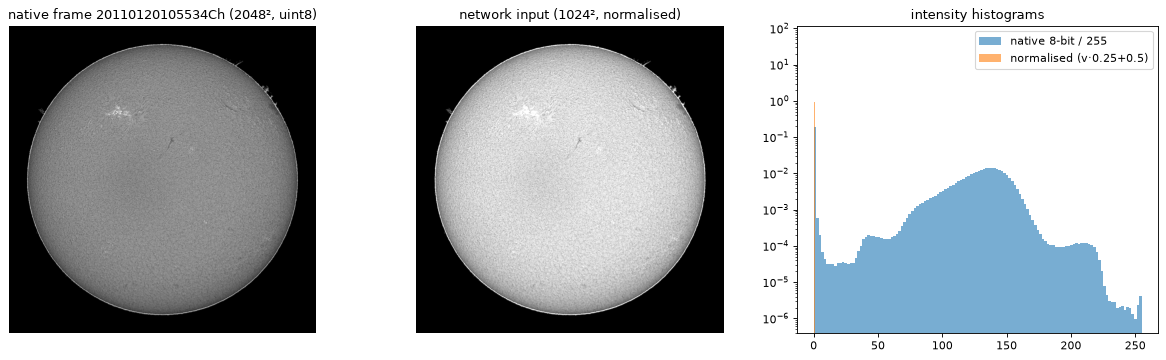

input range [-2.00, 2.00], mean -0.06


In [2]:
key = sorted(test_paths)[0]
gray = read_gray(test_paths[key])
x = model_input(test_paths[key], cfg['inference']['side'])

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].imshow(gray, cmap='gray'); ax[0].set_title(f'native frame {key} (2048², uint8)'); ax[0].axis('off')
ax[1].imshow(x, cmap='gray', vmin=-2, vmax=2); ax[1].set_title('network input (1024², normalised)'); ax[1].axis('off')
ax[2].hist(gray.ravel(), 128, alpha=.6, density=True, label='native 8-bit / 255')
ax[2].hist(((x*.25)+.5).ravel(), 128, alpha=.6, density=True, label='normalised (v·0.25+0.5)')
ax[2].set_yscale('log'); ax[2].legend(); ax[2].set_title('intensity histograms')
plt.tight_layout(); plt.show()
print(f'input range [{x.min():.2f}, {x.max():.2f}], mean {x.mean():.2f}')

## 3. Training (optional; not run by default)

The released weights were trained on one H200 GPU with the scripts in `train/` (details in
`train/README.md`). All 707 labelled frames were split into 5 calendar-month folds
(`configs/folds_full.json`); fold *k*'s networks never saw fold *k*'s frames, which is what makes
the out-of-fold verifier training possible.

1. `prepare_data.py`: model-side image caches and per-annotator soft targets (768 and 1024)
2. `train_convnext_unet.py`: 5 ConvNeXt-T U-Nets, 120 epochs each (about 1.5 h per fold on an H200)
3. `train_r34_unet.py`: 5 ResNet34 U-Nets, 45 + 12 epochs (about 1 h per fold)
4. `build_verifier_data.py`: out-of-fold maps → candidates, 46 features, IoU targets, crops
5. `train_crop_cnn.py`: 5 crop CNNs plus out-of-fold scores
6. `train_gbm.py`: 100 bagged GBMs (`verifier_gbm.pkl`) and the fold-0-excluded copy used in section 6
7. `export_weights.py`: shard the checkpoints into `weights/`

Set `RUN_TRAINING = True` to run the chain. `SMOKE = True` runs every script on a handful of frames
for one epoch (a few minutes on CPU) to check that it works; the full run needs a GPU.

In [3]:
RUN_TRAINING = False
SMOKE = True
work = REPO/'work'/('smoke' if SMOKE else 'full')
smoke = ['--smoke'] if SMOKE else []
py = sys.executable
commands = [[py, 'train/prepare_data.py', '--out', f'{work}/prepared', *smoke]]
for k in range(1 if SMOKE else 5):
    commands += [[py, 'train/train_convnext_unet.py', '--cache', f'{work}/prepared/1024', '--fold', str(k),
                  '--out', f'{work}/runs/cnx_fold{k}', *smoke],
                 [py, 'train/train_r34_unet.py', '--cache768', f'{work}/prepared/768', '--cache1024', f'{work}/prepared/1024',
                  '--fold', str(k), '--out', f'{work}/runs/r34_fold{k}', *smoke]]
commands += [[py, 'train/build_verifier_data.py', '--runs', f'{work}/runs', '--out', f'{work}/verifier_data.npz',
              *(['--smoke', '--from-weights'] if SMOKE else [])],
             [py, 'train/train_crop_cnn.py', '--data', f'{work}/verifier_data.npz', '--out', f'{work}/runs/crop_cnn', *smoke],
             [py, 'train/train_gbm.py', '--data', f'{work}/verifier_data.npz', '--cnn', f'{work}/runs/crop_cnn/cnn_oof_scores.npz',
              '--out', f'{work}/runs/verifier_gbm.pkl', *smoke]]
for c in commands:
    print(' '.join(str(Path(a).relative_to(REPO)) if str(a).startswith(str(REPO)) else str(a) for a in c[1:]))
if RUN_TRAINING:
    import subprocess
    for c in commands:
        subprocess.run(c, cwd=REPO, check=True)

train/prepare_data.py --out work/smoke/prepared --smoke
train/train_convnext_unet.py --cache work/smoke/prepared/1024 --fold 0 --out work/smoke/runs/cnx_fold0 --smoke
train/train_r34_unet.py --cache768 work/smoke/prepared/768 --cache1024 work/smoke/prepared/1024 --fold 0 --out work/smoke/runs/r34_fold0 --smoke
train/build_verifier_data.py --runs work/smoke/runs --out work/smoke/verifier_data.npz --smoke --from-weights
train/train_crop_cnn.py --data work/smoke/verifier_data.npz --out work/smoke/runs/crop_cnn --smoke
train/train_gbm.py --data work/smoke/verifier_data.npz --cnn work/smoke/runs/crop_cnn/cnn_oof_scores.npz --out work/smoke/runs/verifier_gbm.pkl --smoke


## 4. Inference on the test set → `submission.csv`

Per frame: 5 ConvNeXt + 5 ResNet34 networks × 8 views at 1024², then candidates, features,
crop CNNs, GBM and post-processing at 2048². Results are cached per frame in
`outputs/frames_test/`, so an interrupted run resumes. The resulting CSV is compared with the file
we submitted (`reference/submission_F_full_refit_nz1.csv`).

How the saved outputs were produced: the 8-vCPU machine was shared with other jobs during the run.
The frame cache was filled partly by this notebook (the first 47 frames) and partly by helper
processes calling the same `predict_frames` code. The notebook was then executed top to bottom on
that cache. The stored per-frame timings therefore include contention. On the unshared machine
(first 47 frames, 8 threads) the median was 104 s per frame: 102 s for the networks and about 3 s
for everything after them.

In [4]:
t0 = time.perf_counter()
pipe = Pipeline(cfg)
print(f'models loaded in {time.perf_counter()-t0:.1f} s on {pipe.predictor.device}')
frames = predict_frames(pipe, run_paths, OUT/'frames_test', log_every=20)
csv_path = OUT/'submission.csv'
digest = write_submission({k: v['rles'] for k, v in frames.items()}, csv_path)
print(validate_submission(csv_path, test_paths))  # ids checked against all 180 test frames
sec = {s: np.array([f['seconds'][s] for f in frames.values()]) for s in next(iter(frames.values()))['seconds']}
print('seconds per frame (median): ' + ', '.join(f'{s} {np.median(v):.1f}' for s, v in sec.items()))
print(f'compute summed over frames: {sec["total"].sum()/3600:.2f} h for {len(frames)} frames (timings are stored per frame, '
      f'so they survive resumed runs)')

models loaded in 7.5 s on cpu
20/180 frames (0 computed now, 20 from the cache), 0 s elapsed


40/180 frames (0 computed now, 40 from the cache), 0 s elapsed


60/180 frames (0 computed now, 60 from the cache), 0 s elapsed


80/180 frames (0 computed now, 80 from the cache), 0 s elapsed


100/180 frames (0 computed now, 100 from the cache), 0 s elapsed


120/180 frames (0 computed now, 120 from the cache), 0 s elapsed


140/180 frames (0 computed now, 140 from the cache), 0 s elapsed


160/180 frames (0 computed now, 160 from the cache), 0 s elapsed


180/180 frames (0 computed now, 180 from the cache), 0 s elapsed


{'rows': 1088, 'images_with_instances': 177, 'images_without_instances': 3, 'disjoint': True}
seconds per frame (median): networks 155.0, candidates_features 0.2, verifier 2.9, postprocess_encode 0.4, total 159.6
compute summed over frames: 8.80 h for 180 frames (timings are stored per frame, so they survive resumed runs)


In [5]:
REF = REPO/'reference'/'submission_F_full_refit_nz1.csv'
ref, new = read_submission(REF), read_submission(csv_path)
print('sha256 submitted :', sha256(REF))
print('sha256 reproduced:', digest, '-> IDENTICAL FILE' if digest == sha256(REF) else '-> files differ, comparing masks')
same_frames = sum(ref.get(k, []) == new.get(k, []) for k in run_paths)
n_ref = sum(len(ref.get(k, [])) for k in run_paths)
print(f'frames with identical masks: {same_frames}/{len(run_paths)};  masks: reproduced {sum(map(len, new.values()))}, submitted {n_ref}')
if digest != sha256(REF):
    ious = []
    for k in run_paths:
        a = [{'size': [2048, 2048], 'counts': r.encode()} for r in ref.get(k, [])]
        b = [{'size': [2048, 2048], 'counts': r.encode()} for r in new.get(k, [])]
        if a and b:
            m = np.asarray(cm.iou(b, a, [0]*len(a)))
            ious.extend(m.max(0).tolist())
        else:
            ious.extend([0.]*len(a))
    ious = np.array(ious)
    print(f'submitted masks with an identical reproduced mask: {(ious == 1).mean():.4f}; with IoU > 0.5: {(ious > .5).mean():.4f}')
    # same frames, same counts and order: compare mask k with mask k pixel by pixel
    dec = lambda r: cm.decode({'size': [2048, 2048], 'counts': r.encode()}).astype(bool)
    pairs = [(x, y) for k in run_paths for x, y in zip(ref.get(k, []), new.get(k, [])) if x != y]
    px = [int((dec(x) ^ dec(y)).sum()) for x, y in pairs]
    total = sum(int(a) for k in run_paths for a in cm.area([{'size': [2048, 2048], 'counts': r.encode()} for r in ref.get(k, [])]) if ref.get(k))
    print(f'{len(pairs)} masks differ from the submitted ones, by {sum(px)} pixels in total '
          f'(max {max(px, default=0)} per mask) out of {total} submitted mask pixels')

sha256 submitted : df7e63f7bc297d511ae1fce05bc62da17b69bb4ec6845d9b3bb96fbafd476c5e
sha256 reproduced: ac0abef8c9e49e7ca7a6565947490c4403f0fb813e01aaf5d0ab5a9d11fa510a -> files differ, comparing masks
frames with identical masks: 144/180;  masks: reproduced 1088, submitted 1088
submitted masks with an identical reproduced mask: 0.9614; with IoU > 0.5: 1.0000


42 masks differ from the submitted ones, by 44 pixels in total (max 2 per mask) out of 2268421 submitted mask pixels


## 5. Post-processing explained

The ensemble map is thresholded at 0.4 and split into 8-connected **candidates** (≥ 150 px, holes filled).
Each candidate gets 46 features (shape, probabilities, photometry, agreement between TTA and single
view, position on the disk, neighbours, votes of the ResNet34 ensemble) and a crop-CNN score. A bagged
GBM predicts **u**, the candidate's expected matched IoU averaged over annotators (0 if unmatched),
i.e. its share of the PQ numerator. Keeping a candidate helps PQ when u exceeds about PQ/2, hence
**τ = 0.25** (selected on calibration months before the full refit).

Kept candidates are then re-outlined (**nz1**): among the nested threshold levels 0.25 … 0.70 of the
same map, each candidate takes the one with the highest *expected* IoU, treating the map (which was
trained on the annotator-mean target) as the probability that an annotator includes a pixel.
Growth is confined to the candidate's Voronoi territory (≤ 16 px), so instances stay disjoint.
Steps are listed in the config (`postprocess.steps`) and can be extended.

20130104104234Ch: 20 candidates, kept 9  (101 s for this frame)


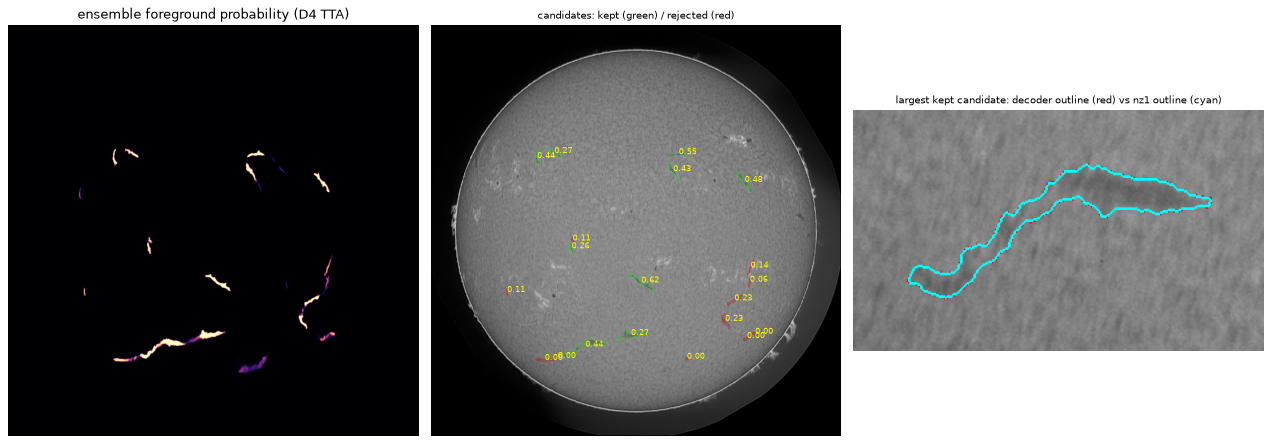

In [6]:
# pick the test frame with the most candidates and rerun it in memory to show the intermediate maps
key = max(frames, key=lambda k: len(frames[k]['u']))
t0 = time.perf_counter()
maps = pipe.predictor(test_paths[key]); gray = read_gray(test_paths[key])
res = pipe.process(key, gray, maps)
print(f'{key}: {len(res.u)} candidates, kept {res.keep.sum()}  ({time.perf_counter()-t0:.0f} s for this frame)')

fig, ax = plt.subplots(1, 3, figsize=(16, 5.6))
ax[0].imshow(maps['decode'][0], cmap='magma', vmin=0, vmax=1); ax[0].set_title('ensemble foreground probability (D4 TTA)'); ax[0].axis('off')
kept = np.where(np.isin(res.candidates, np.flatnonzero(res.keep)+1), res.candidates, 0)
rejected = np.where(np.isin(res.candidates, np.flatnonzero(~res.keep)+1), res.candidates, 0)
viz.overlay(gray, [(kept, (0, 1, 0)), (rejected, (1, 0, 0))], ax[1], 'candidates: kept (green) / rejected (red)')
from scipy import ndimage as ndi
for j, c in enumerate(ndi.center_of_mass(res.candidates > 0, res.candidates, range(1, len(res.u)+1))):
    ax[1].text(c[1], c[0], f'{res.u[j]:.2f}', color='yellow', fontsize=7)
j = int(np.argmax(np.where(res.keep, [(res.candidates == i+1).sum() for i in range(len(res.u))], 0)))
ys, xs = np.nonzero(res.candidates == j+1); pad = 40
crop = (slice(max(ys.min()-pad, 0), ys.max()+pad), slice(max(xs.min()-pad, 0), xs.max()+pad))
final_id = int(np.cumsum(res.keep)[j])
viz.overlay(gray, [((res.candidates == j+1).astype(int), (1, 0, 0)), ((res.instances == final_id).astype(int), (0, 1, 1))],
            ax[2], 'largest kept candidate: decoder outline (red) vs nz1 outline (cyan)', crop=crop)
plt.tight_layout(); plt.show()

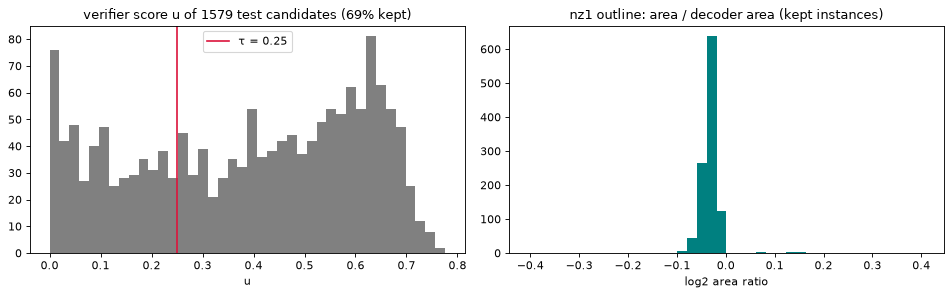

median area ratio 0.978; grown 1%, shrunk 92%, unchanged 7%


In [7]:
# test-set statistics of the verifier and of the outline step
u_all = np.concatenate([f['u'] for f in frames.values()]); keep_all = np.concatenate([f['keep'] for f in frames.values()]).astype(bool)
ratio = []
for f in frames.values():
    cand = [r for r, k in zip(f['candidate_rles'], f['keep']) if k]
    a0 = cm.area([{'size': [2048, 2048], 'counts': r.encode()} for r in cand]) if cand else []
    a1 = cm.area([{'size': [2048, 2048], 'counts': r.encode()} for r in f['rles']]) if f['rles'] else []
    ratio.extend(np.asarray(a1)/np.asarray(a0))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(u_all, 40, color='gray'); ax[0].axvline(cfg['verifier']['tau'], color='crimson', label='τ = 0.25')
ax[0].set(title=f'verifier score u of {len(u_all)} test candidates ({keep_all.mean():.0%} kept)', xlabel='u'); ax[0].legend()
ax[1].hist(np.log2(ratio), 40, color='teal'); ax[1].set(title='nz1 outline: area / decoder area (kept instances)', xlabel='log2 area ratio')
plt.tight_layout(); plt.show()
print(f'median area ratio {np.median(ratio):.3f}; grown {np.mean(np.array(ratio) > 1):.0%}, shrunk {np.mean(np.array(ratio) < 1):.0%}, unchanged {np.mean(np.array(ratio) == 1):.0%}')

## 6. Evaluation on held-out labelled frames

The submitted networks were refit on all 707 labelled frames, so no labelled frame is unseen by
the full ensemble. For an honest check we use the **142 frames of fold 0** and only models that
never saw them: ConvNeXt fold 0, ResNet34 fold 0 and crop-CNN fold 0, plus a GBM refit without
fold 0's candidates (`weights/verifier_gbm_without_fold0.pkl`). This is a single-fold pipeline, so it
is a slightly pessimistic estimate of the 5-model ensemble.

The metric follows the host's self-evaluation notebook exactly: every annotator's record of a frame is
scored separately against the same predictions; TP = pairs with IoU > 0.5; PQ pooled over all records.
Three stages are scored: all candidates, after the verifier, and after the nz1 outline (the final output).

In [8]:
del pipe
folds = json.loads(resolve(cfg['data']['folds']).read_text())['folds']
held = sorted(folds[0]['heldout_sources'])[:MAX_FRAMES]
held_paths = {k: train_paths[k] for k in held}
eval_pipe = Pipeline(cfg, segmenters=['cnx_fold0'], voters=['r34_fold0'], crop_cnns=['crop_cnn_fold0'],
                     gbm='verifier_gbm_without_fold0.pkl')
held_frames = predict_frames(eval_pipe, held_paths, OUT/'frames_heldout_fold0', log_every=20)
gt = load_ground_truth(data_path(cfg, 'train_annotations'), set(held))
print(f'{len(held)} frames, {sum(map(len, gt.values()))} annotator records, '
      f'{sum(len(r) for v in gt.values() for _, r in v)} GT filaments')

stages = {
    'all candidates (decoder outline)': {k: f['candidate_rles'] for k, f in held_frames.items()},
    'verifier (u >= 0.25)':             {k: [r for r, kp in zip(f['candidate_rles'], f['keep']) if kp] for k, f in held_frames.items()},
    'verifier + nz1 outline (final)':   {k: f['rles'] for k, f in held_frames.items()},
}
results = {name: evaluate(gt, pred) for name, pred in stages.items()}
for name, r in results.items():
    o = r['overall']
    print(f"{name:34s} PQ {o['pq']:.4f}  SQ {o['sq']:.4f}  RQ {o['rq']:.4f}  TP {o['tp']:4d}  FP {o['fp']:4d}  FN {o['fn']:4d}")

20/142 frames (0 computed now, 20 from the cache), 0 s elapsed


40/142 frames (0 computed now, 40 from the cache), 0 s elapsed


60/142 frames (0 computed now, 60 from the cache), 0 s elapsed


80/142 frames (0 computed now, 80 from the cache), 0 s elapsed


100/142 frames (0 computed now, 100 from the cache), 0 s elapsed


120/142 frames (0 computed now, 120 from the cache), 0 s elapsed


140/142 frames (0 computed now, 140 from the cache), 0 s elapsed


142/142 frames (0 computed now, 142 from the cache), 0 s elapsed


142 frames, 236 annotator records, 1633 GT filaments
all candidates (decoder outline)   PQ 0.4239  SQ 0.6751  RQ 0.6279  TP 1118  FP  810  FN  515
verifier (u >= 0.25)               PQ 0.4611  SQ 0.6791  RQ 0.6790  TP 1028  FP  367  FN  605
verifier + nz1 outline (final)     PQ 0.4641  SQ 0.6808  RQ 0.6816  TP 1032  FP  363  FN  601


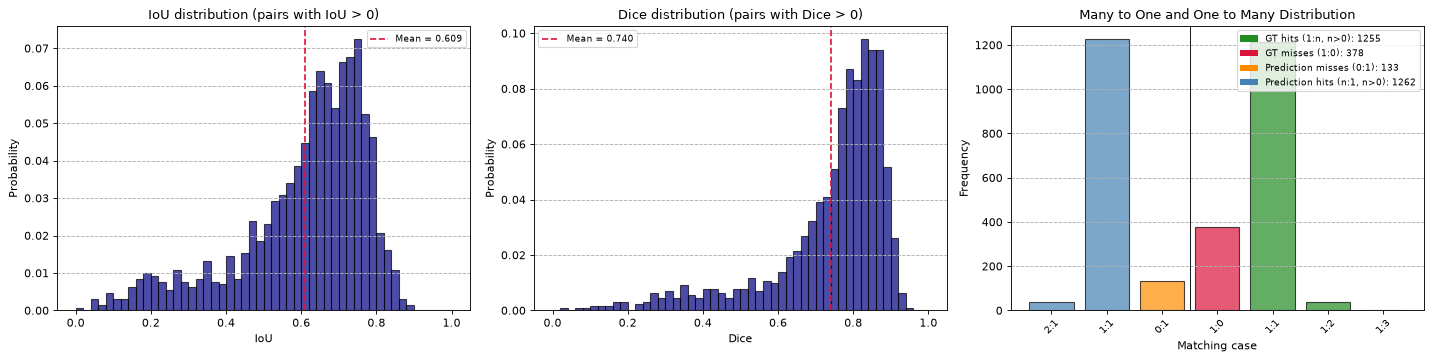

GT -> #overlapping predictions: {0: 378, 1: 1215, 2: 37, 3: 3}
prediction -> #overlapping GT: {0: 133, 1: 1226, 2: 36}


In [9]:
final = results['verifier + nz1 outline (final)']
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
viz.plot_distribution(final['positive_ious'], 'IoU distribution (pairs with IoU > 0)', 'IoU', ax[0])
viz.plot_distribution(final['positive_dices'], 'Dice distribution (pairs with Dice > 0)', 'Dice', ax[1])
viz.plot_relations(final['gt_degree'], final['pred_degree'], ax[2])
plt.tight_layout(); plt.show()
g, p = final['gt_degree'], final['pred_degree']
print('GT -> #overlapping predictions:', dict(sorted(g.items())))
print('prediction -> #overlapping GT:', dict(sorted(p.items())))

## 7. Overlays

Held-out frames: every annotator's filaments (one colour per annotator) and our final instances (cyan).
Then two test frames with our predictions only (no labels exist for them). Each row shows the full frame and a zoom on the
largest predicted filament.

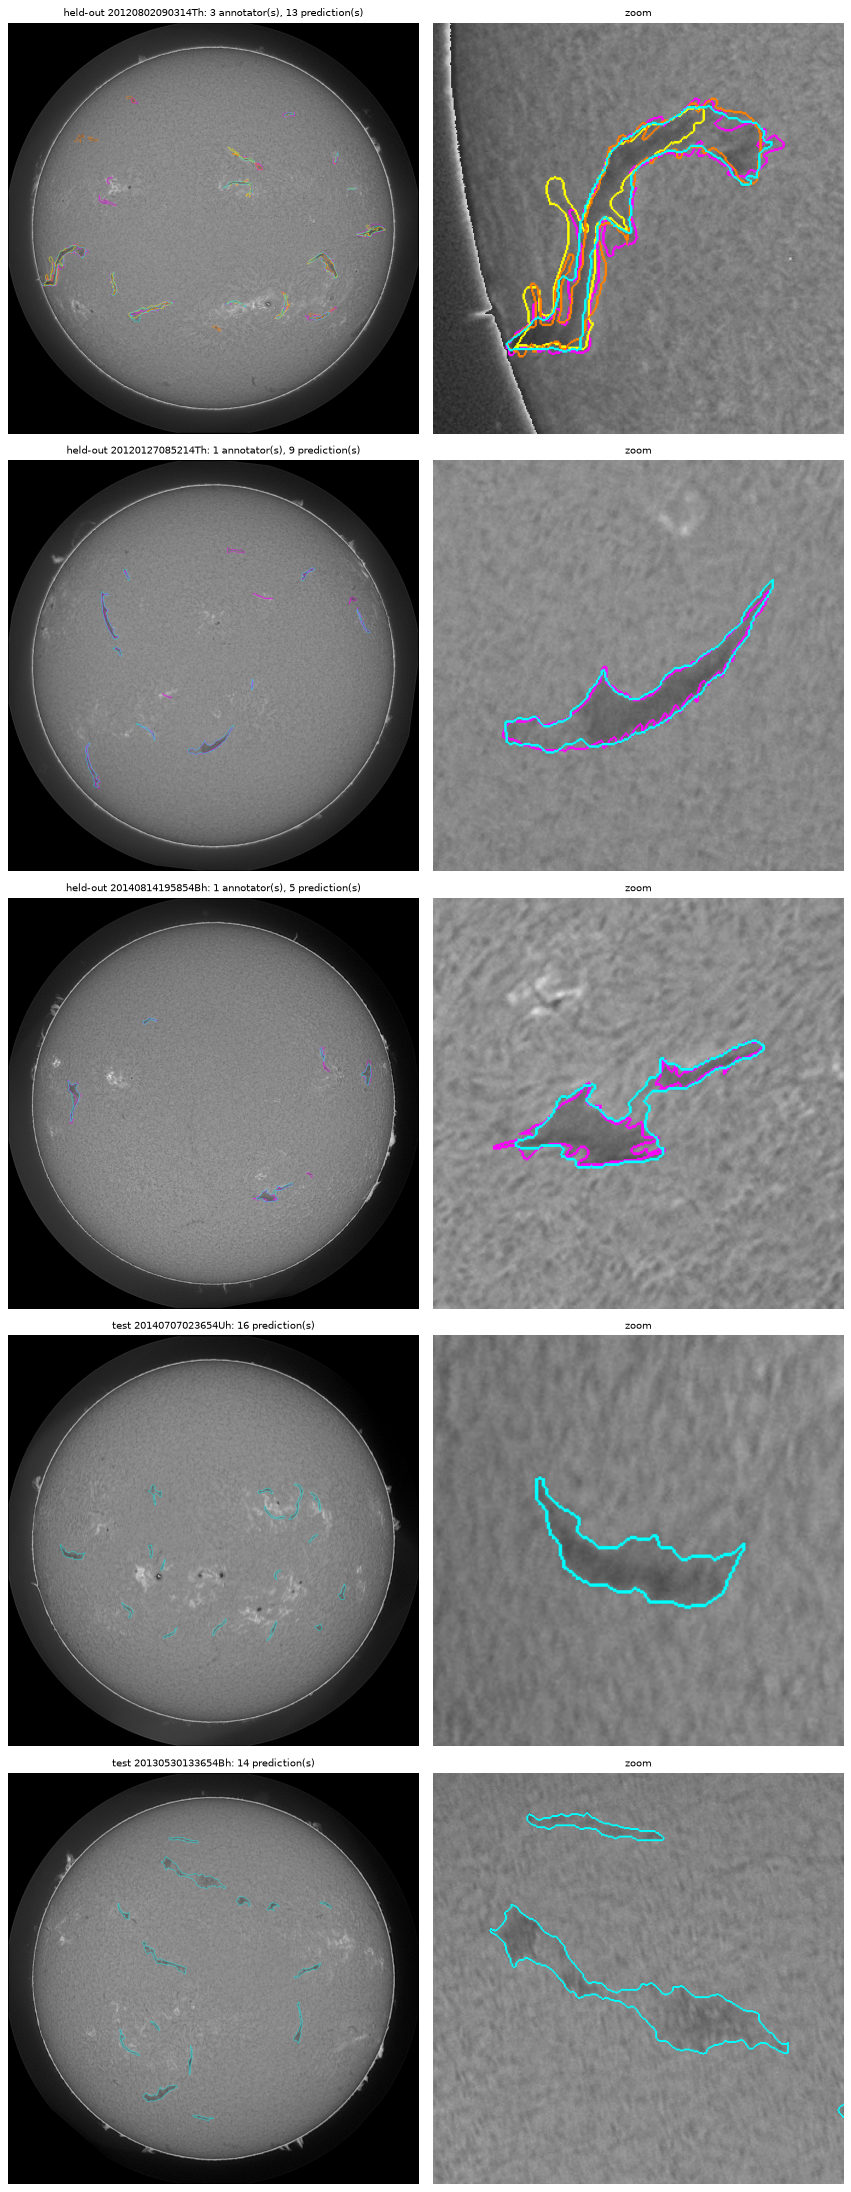

In [10]:
def rles_to_labels(rles):
    lab = np.zeros((2048, 2048), np.int32)
    for i, r in enumerate(rles, 1):
        lab[cm.decode({'size': [2048, 2048], 'counts': r.encode() if isinstance(r, str) else r}).astype(bool)] = i
    return lab

def zoom_box(lab, pad=60):
    if lab.max() == 0:
        return (slice(512, 1536), slice(512, 1536))
    big = np.argmax(np.bincount(lab.ravel())[1:])+1
    ys, xs = np.nonzero(lab == big)
    cy, cx, h = (ys.min()+ys.max())//2, (xs.min()+xs.max())//2, max(np.ptp(ys), np.ptp(xs))//2+pad
    return (slice(max(cy-h, 0), cy+h), slice(max(cx-h, 0), cx+h))

colours = [(1, 0, 1), (1, 1, 0), (1, .5, 0), (0, 1, 0)]
by_records = sorted(held, key=lambda k: -sum(len(r) for _, r in gt[k]))
show = [by_records[0], by_records[len(by_records)//3], by_records[2*len(by_records)//3]]
fig, ax = plt.subplots(len(show)+2, 2, figsize=(11, 5.5*(len(show)+2)))
for row, k in enumerate(show):
    g = read_gray(train_paths[k]); pred = rles_to_labels(held_frames[k]['rles'])
    layers = [(rles_to_labels([r['counts'] for r in rl]), colours[i % 4]) for i, (_, rl) in enumerate(gt[k])] + [(pred, (0, 1, 1))]
    viz.overlay(g, layers, ax[row, 0], f'held-out {k}: {len(gt[k])} annotator(s), {pred.max()} prediction(s)')
    viz.overlay(g, layers, ax[row, 1], 'zoom', crop=zoom_box(pred))
for row, k in enumerate(sorted(frames, key=lambda k: -len(frames[k]['rles']))[:2], len(show)):
    g = read_gray(test_paths[k]); pred = rles_to_labels(frames[k]['rles'])
    viz.overlay(g, [(pred, (0, 1, 1))], ax[row, 0], f'test {k}: {pred.max()} prediction(s)')
    viz.overlay(g, [(pred, (0, 1, 1))], ax[row, 1], 'zoom', crop=zoom_box(pred))
plt.tight_layout(); plt.show()

## Notes

- The weights are stored as fp32 safetensors shards (each < 95 MB) and verified against the SHA-256
  recorded in `weights/manifest.json` when loaded.
- Data rules: only the official training annotations were used for training (no external labels,
  no other GONG frames); inference reads nothing but the test image itself.
- Almost all of the CPU time is the 10 networks × 8 TTA views; with a CUDA GPU (`inference.device: auto`)
  that part becomes small. Everything after the networks is CPU code and takes a few seconds per frame.